# Spectral Analysis - Independent Work
by Leticia Vieira da Silva
Independent Work at Princeton University (Spring 2025) investigating the effects of growth temperature in intersubband transitions in quantum wells.

In [1]:
# libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
from scipy.optimize import curve_fit
import os

In [2]:
# base directory and folders
base_dir = r"C:\Users\letii\Documents\IW_data"
bg_folder = "20250403_backgrounds"
sample_folders = [
    "20250327_p1_7_25_1_612",
    "20250403_p2_6_25_1_420",
    "20250327_p2_5_25_1_530",
    "20250327_p3_13_25_1_368",
    "20250327_p3_13_25_2_290",
    "20250327_p3_14_25_1_640"
]

# Ensure plot directory exists
os.makedirs(os.path.join(base_dir, "plots"), exist_ok=True)


In [3]:
# Helper function to extract temperature
def get_sample_temp(sample_name):
    return int(os.path.basename(sample_name)[-3:])

In [4]:
# Safeguarded Lorentzian function to prevent SIGFPE crashes
def lorentzian(v, v0, HWHM, A, y0):
    safe_HWHM = np.maximum(np.abs(HWHM), 1e-15)
    return y0 + (A * safe_HWHM**2) / ((v - v0)**2 + safe_HWHM**2)

# dictionary to store processing results
all_results = {}


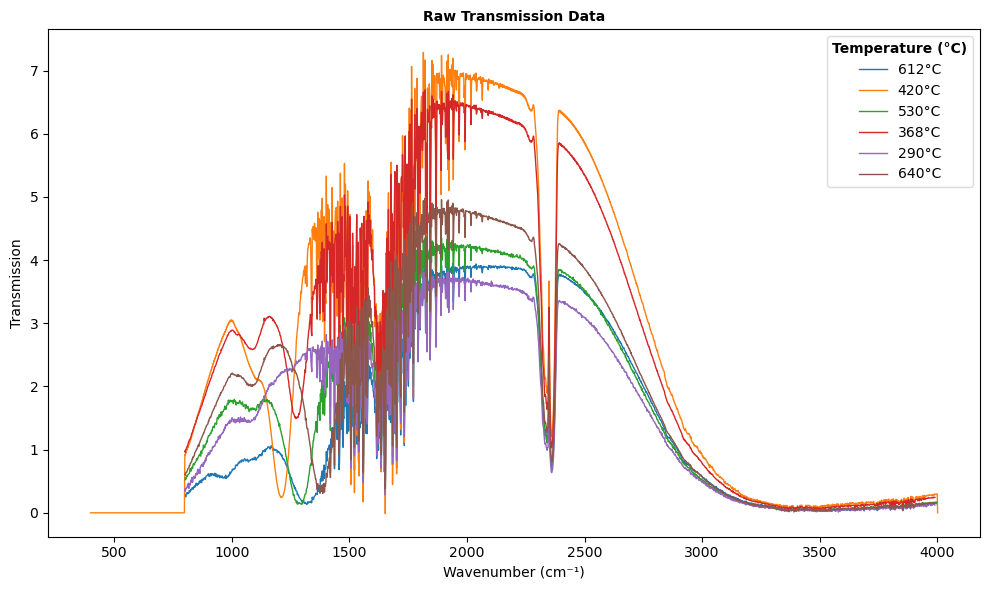

In [5]:
def plot_raw_data(folders):
    fig_raw, ax_raw = plt.subplots(figsize=(10, 6))
    colors = plt.cm.inferno(np.linspace(0, 0.8, len(folders)))
    
    for sample_folder, color in zip(folders, colors):
        sample_paths = glob.glob(os.path.join(base_dir, sample_folder, "*.csv"))
        if sample_paths:
            data = pd.read_csv(sample_paths[0], header=None, names=['Wavenumber', 'Transmission'])
            temp = get_sample_temp(sample_folder)
            ax_raw.plot(data['Wavenumber'], data['Transmission'], '-', linewidth=1, label=f'{temp}°C')
    
    ax_raw.set_title('Raw Transmission Data', fontsize='medium', fontweight='bold')
    ax_raw.set_xlabel('Wavenumber (cm⁻¹)')
    ax_raw.set_ylabel('Transmission')
    #ax_raw.set_xlim(1600, 800)
    
    legend = ax_raw.legend(loc='upper right', framealpha=0.7, title='Temperature (°C)')
    legend.get_title().set_fontweight('bold')
    fig_raw.tight_layout()
    plt.show()

plot_raw_data(sample_folders)

Generating angle analysis breakdown for 20250327_p2_5_25_1_530...


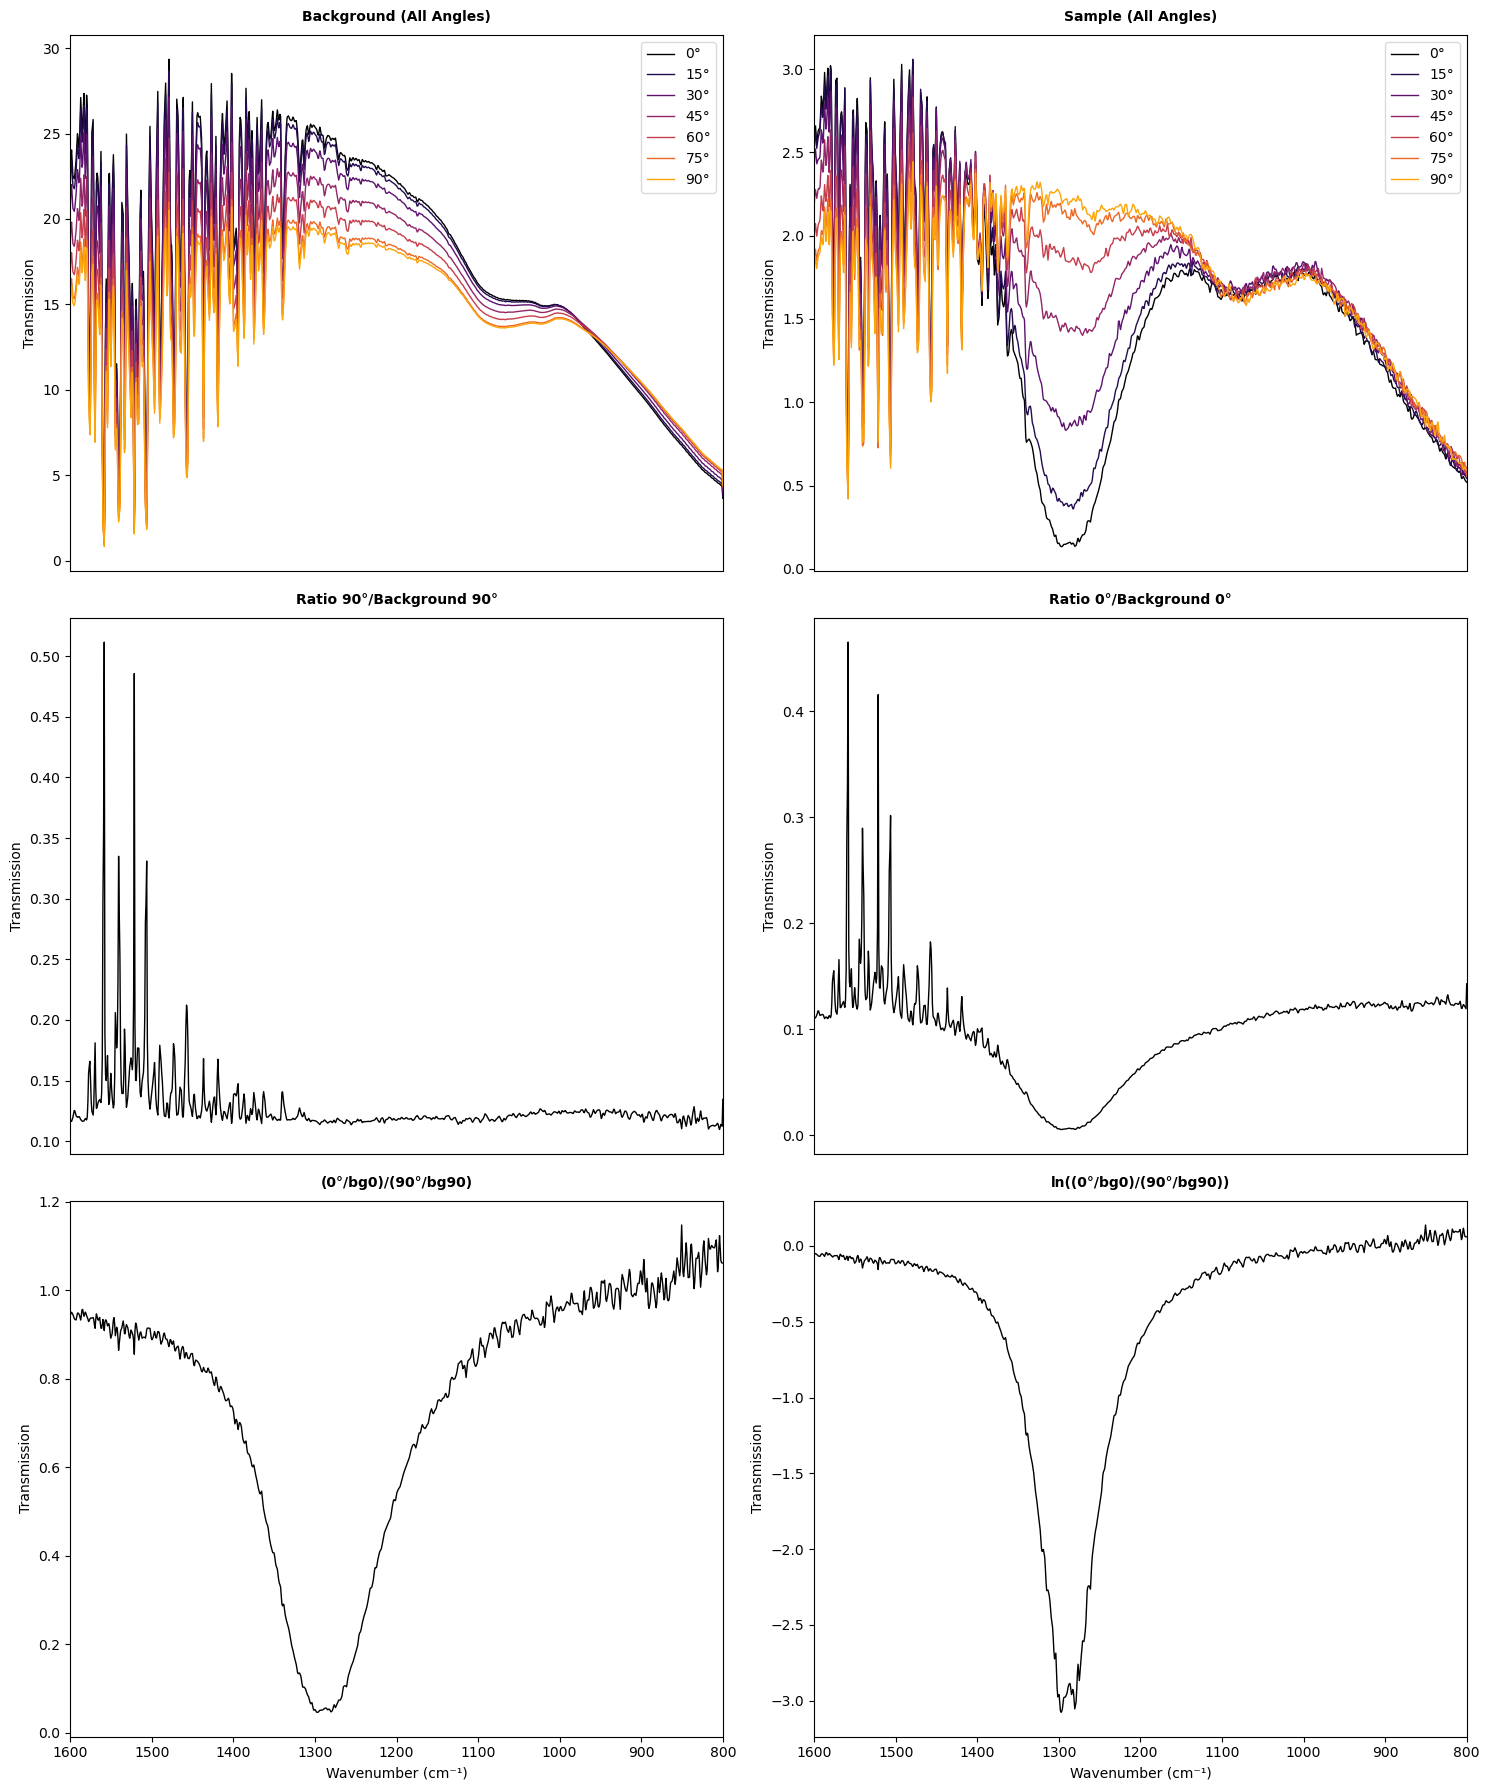

In [ ]:
# Angle Analysis Breakdown
sample_name = "20250327_p2_5_25_1_530"
print(f"Generating angle analysis breakdown for {sample_name}...")

fig_angles, axs = plt.subplots(3, 2, figsize=(15, 18))
axs = axs.ravel()

sample_paths = sorted(glob.glob(os.path.join(base_dir, sample_name, "*.csv")))
bg_paths = sorted(glob.glob(os.path.join(base_dir, bg_folder, "*.csv")))
angles = np.arange(0, 91, 15)

colors = plt.cm.inferno(np.linspace(0, 0.8, len(angles)))
common_wavenumbers = np.linspace(800, 1600, 1000)
angle_data = {}

# Plot 1: Background & Plot 2: Sample
for angle, color, bg_file, sample_file in zip(angles, colors, bg_paths, sample_paths):
    # Background
    bg = pd.read_csv(bg_file, header=None, names=['Wavenumber', 'Transmission'])
    bg_interp = np.interp(common_wavenumbers, bg['Wavenumber'], bg['Transmission'])
    axs[0].plot(common_wavenumbers, bg_interp, '-', color=color, linewidth=1, label=f'{angle}°')
    angle_data[angle] = {'background': bg_interp}
    
    # Sample
    sample = pd.read_csv(sample_file, header=None, names=['Wavenumber', 'Transmission'])
    sample_interp = np.interp(common_wavenumbers, sample['Wavenumber'], sample['Transmission'])
    axs[1].plot(common_wavenumbers, sample_interp, '-', color=color, linewidth=1, label=f'{angle}°')
    angle_data[angle]['sample'] = sample_interp

# Plot 3 & 4: Raw Ratios
ratio_90 = angle_data[90]['sample'] / angle_data[90]['background']
axs[2].plot(common_wavenumbers, ratio_90, 'k-', linewidth=1)

ratio_0 = angle_data[0]['sample'] / angle_data[0]['background']
axs[3].plot(common_wavenumbers, ratio_0, 'k-', linewidth=1)

# Plot 5: Final Ratio
ratio_final = ratio_0 / ratio_90
axs[4].plot(common_wavenumbers, ratio_final, 'k-', linewidth=1)

# Plot 6: Natural Log
log_ratio = np.log(ratio_final)
axs[5].plot(common_wavenumbers, log_ratio, 'k-', linewidth=1)

# Styling the 6 panels
titles = ['Background (All Angles)', 'Sample (All Angles)', 
          'Ratio 90°/Background 90°', 'Ratio 0°/Background 0°',
          '(0°/bg0)/(90°/bg90)', 'ln((0°/bg0)/(90°/bg90))']

for i, (ax, title) in enumerate(zip(axs, titles)):
    ax.set_title(title, fontsize='medium', fontweight='bold', pad=10)
    ax.set_ylabel('Transmission')
    ax.set_xlim(1600, 800)
    
    if i >= 4:
        ax.set_xlabel('Wavenumber (cm⁻¹)')
    else:
        ax.set_xticklabels([])
        ax.set_xticks([])

axs[0].legend(loc='upper right', framealpha=0.7)
axs[1].legend(loc='upper right', framealpha=0.7)
fig_angles.tight_layout()
plt.show()

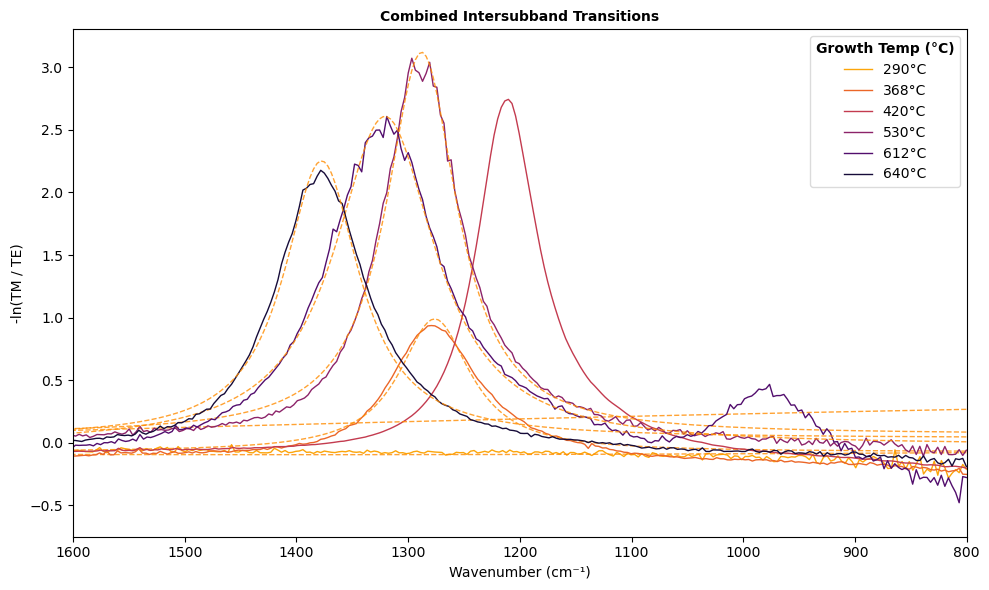

In [11]:
# Cell 3.5: Combined Plot of all samples
fig_combined, ax_combined = plt.subplots(figsize=(10, 6))
ax_combined.set_title('Combined Intersubband Transitions', fontsize='medium', fontweight='bold')
ax_combined.set_xlabel('Wavenumber (cm⁻¹)')
ax_combined.set_ylabel('-ln(TM / TE)')
ax_combined.set_xlim(1600, 800)

# Sort samples by temperature to keep colors sequential
sorted_samples = sorted(all_results.items(), key=lambda x: get_sample_temp(x[0]))
colors = plt.cm.inferno(np.linspace(0.8, 0.1, len(sorted_samples)))

for (sample_name, results), color in zip(sorted_samples, colors):
    if results.get('parameters'):
        temp = get_sample_temp(sample_name)
        wv_clean = results['wavenumbers']
        ratio_clean = results['ratio']
        fit_curve = results['fit']
        
        # Plot interpolated data
        ax_combined.plot(wv_clean, ratio_clean, '-', color=color, linewidth=1, label=f'{temp}°C')
        
        # Plot corresponding fit (hidden from legend)
        ax_combined.plot(wv_clean, fit_curve, '--', color='darkorange', linewidth=1, alpha=0.8, label='_nolegend_')

# Style the global legend
legend = ax_combined.legend(loc='upper right', framealpha=0.7, title='Growth Temp (°C)')
legend.get_title().set_fontweight('bold')

fig_combined.tight_layout()
plt.show()

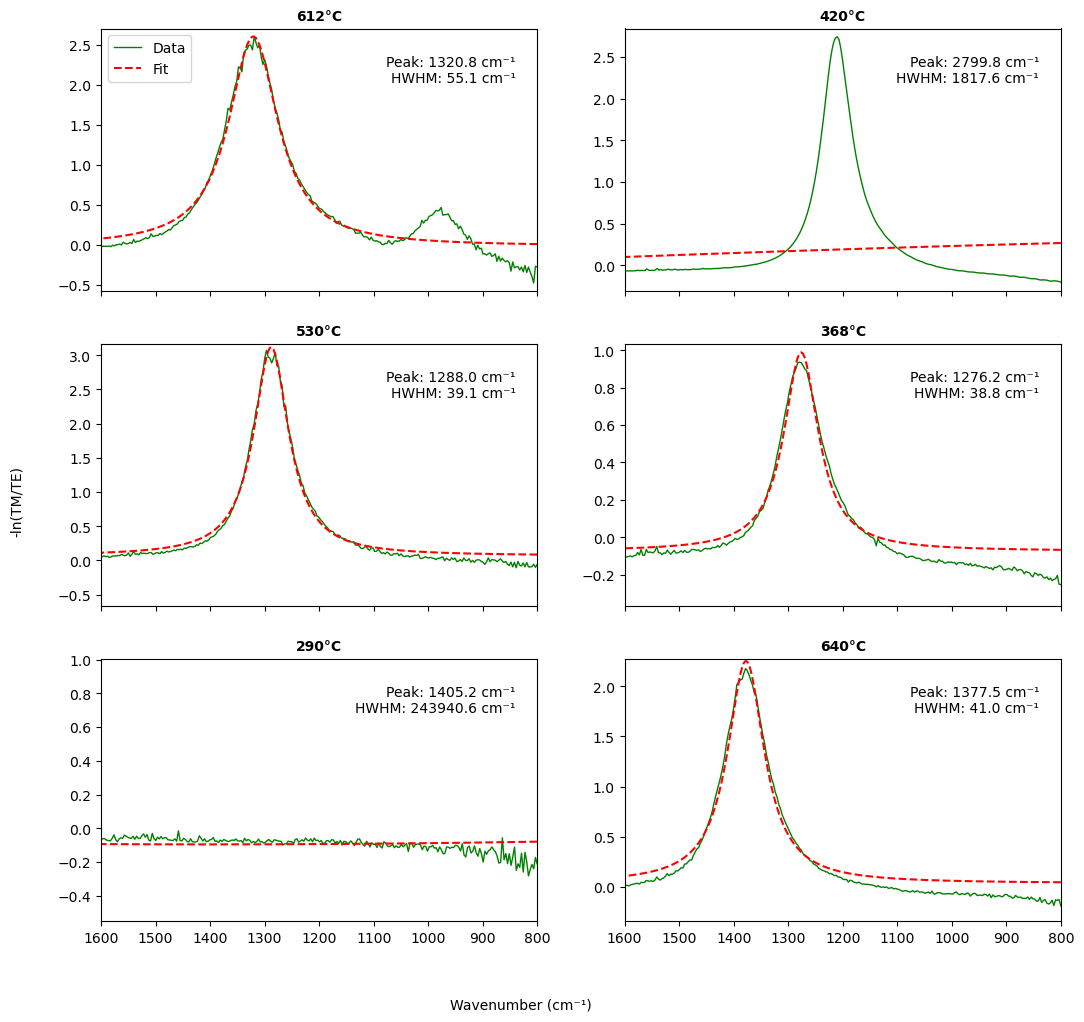

In [ ]:
# Processing, Normalization, and Fitting
p0_values = {
    "p3-14-25-1": [1300, 100, 4, -0.1],
    "p1-7-25-1": [1300, 100, 4, -0.1],
    "p2-5-25-1": [1275, 50, 3, 0],
    "p2-6-25-1": [1230, 40, 3, -0.1],
    "p3-13-25-1": [1278, 50, 0.8, -0.1],
    "p3-13-25-2": [1378, 50, 3, -1],
}

n_samples = len(sample_folders)
n_rows = (n_samples + 1) // 2 
fig_fits, axs = plt.subplots(n_rows, 2, figsize=(12, 3.5*n_rows), sharex=True)
axs = axs.flatten()
fig_fits.subplots_adjust(left=0.15, right=0.95, bottom=0.1, top=0.95, hspace=0.2)

bg_paths = sorted(glob.glob(os.path.join(base_dir, bg_folder, "*.csv")))

for idx, sample_folder in enumerate(sample_folders):
    sample_paths = sorted(glob.glob(os.path.join(base_dir, sample_folder, "*.csv")))
    
    if not sample_paths or not bg_paths:
        continue
        
    data_dict = {}
    target_files = {0: (sample_paths[0], bg_paths[0]), 90: (sample_paths[-1], bg_paths[-1])}
    
    for angle, (s_file, b_file) in target_files.items():
        sample = pd.read_csv(s_file, header=None, names=['Wavenumber', 'Absorbance'])
        bg = pd.read_csv(b_file, header=None, names=['Wavenumber', 'Absorbance'])
        bg = bg[(bg['Wavenumber'] >= 800) & (bg['Wavenumber'] < 4000)].reset_index(drop=True)
        
        common_wv = np.linspace(
            max(sample['Wavenumber'].min(), bg['Wavenumber'].min()),
            min(sample['Wavenumber'].max(), bg['Wavenumber'].max()), 1000)
        
        data_dict[angle] = {
            'wavenumber': common_wv,
            'sample': np.interp(common_wv, sample['Wavenumber'], sample['Absorbance']),
            'background': np.interp(common_wv, bg['Wavenumber'], bg['Absorbance']) / 10
        }

    ratio_0deg = np.where(data_dict[0]['sample'] / data_dict[0]['background'] <= 0, 1e-10, data_dict[0]['sample'] / data_dict[0]['background'])
    ratio_90deg = np.where(data_dict[90]['sample'] / data_dict[90]['background'] <= 0, 1e-10, data_dict[90]['sample'] / data_dict[90]['background'])
    
    ratio_final = np.where(ratio_0deg / ratio_90deg <= 0, 1e-10, ratio_0deg / ratio_90deg)
    ln_ratio_final = -np.log(ratio_final)
    
    mask = np.isfinite(ln_ratio_final)
    wv_clean = data_dict[0]['wavenumber'][mask]
    ratio_clean = ln_ratio_final[mask]
    
    #fit Preparation
    sample_name = os.path.basename(sample_folder)
    sample_parts = sample_name.split('_', 1)
    sample_base = f"p{sample_parts[1].replace('_', '-')}" if len(sample_parts) > 1 else sample_name
    
    p0 = p0_values.get(sample_base, [1300, 50, 3, 0])
    
    try:
        popt, _ = curve_fit(lorentzian, wv_clean, ratio_clean, p0=p0, method='lm')
        
        all_results[sample_name] = {
            'wavenumbers': wv_clean,
            'ratio': ratio_clean,
            'fit': lorentzian(wv_clean, *popt),
            'parameters': {'peak': popt[0], 'FWHM': 2 * abs(popt[1]), 'amplitude': popt[2], 'offset': popt[3]}
        }
        
        # Plotting
        ax = axs[idx]
        ax.plot(wv_clean, ratio_clean, 'g-', linewidth=1, label='Data')
        ax.plot(wv_clean, all_results[sample_name]['fit'], 'r--', linewidth=1.5, label='Fit')
        ax.set_title(f'{get_sample_temp(sample_folder)}°C', fontsize=10, fontweight='bold')
        ax.set_ylim(min(ratio_clean) - 0.1, max(ratio_clean) + 0.1)
        ax.invert_xaxis()
        
        ax.annotate(f"Peak: {popt[0]:.1f} cm⁻¹\nHWHM: {abs(popt[1]):.1f} cm⁻¹",
                    xy=(0.95, 0.90), xycoords='axes fraction', ha='right', va='top',
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))
        if idx == 0: ax.legend(loc='upper left')
            
    except Exception as e:
        print(f"Fitting failed for {sample_folder}: {e}")

fig_fits.text(0.5, 0.02, 'Wavenumber (cm⁻¹)', ha='center', va='center')
fig_fits.text(0.08, 0.5, '-ln(TM/TE)', va='center', ha='center', rotation='vertical')
for ax in axs: ax.set_xlim(1600, 800)
plt.show()

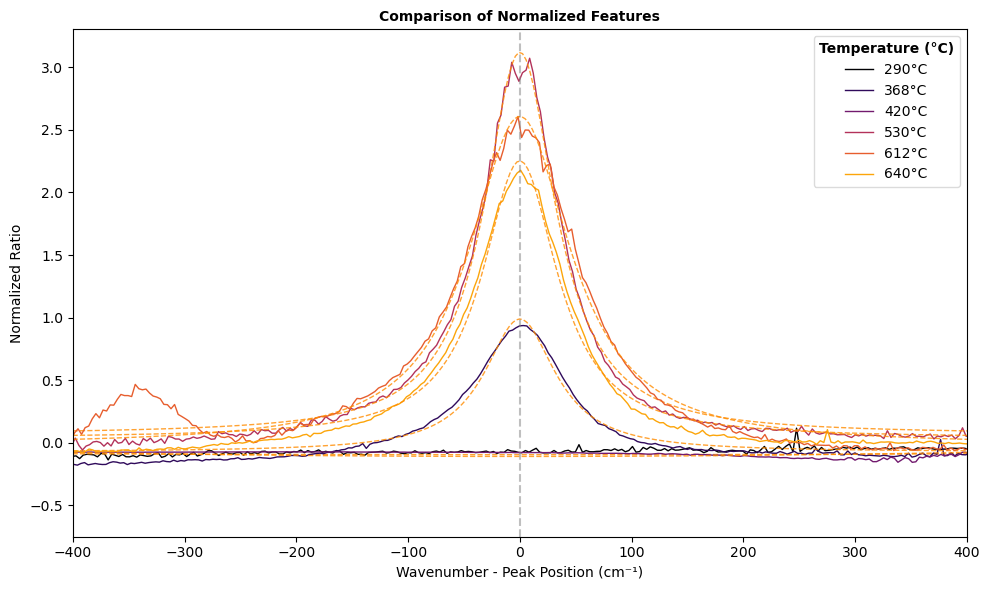

In [ ]:
#Aligned Spectra Comparison
fig_aligned, ax_aligned = plt.subplots(figsize=(10, 6))
ax_aligned.set_title('Comparison of Normalized Features', fontsize='medium', fontweight='bold')

sorted_samples = sorted(all_results.items(), key=lambda x: get_sample_temp(x[0]))
colors = plt.cm.inferno(np.linspace(0, 0.8, len(sorted_samples)))

for (sample_name, results), color in zip(sorted_samples, colors):
    if results.get('parameters'):
        wv = results['wavenumbers']
        ratio = results['ratio']
        peak_pos = results['parameters']['peak']
        
        temp = get_sample_temp(sample_name)
        ax_aligned.plot(wv - peak_pos, ratio, '-', linewidth=1, color=color, label=f'{temp}°C')
        fit_y = lorentzian(wv, peak_pos, results['parameters']['FWHM']/2, 
                           results['parameters']['amplitude'], results['parameters']['offset'])
        ax_aligned.plot(wv - peak_pos, fit_y, '--', color='darkorange', linewidth=1, alpha=0.8)

ax_aligned.set_xlabel('Wavenumber - Peak Position (cm⁻¹)')
ax_aligned.set_ylabel('Normalized Ratio')
ax_aligned.set_xlim(-400, 400)
ax_aligned.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
legend = ax_aligned.legend(loc='upper right', framealpha=0.7, title='Temperature (°C)')
legend.get_title().set_fontweight('bold')
fig_aligned.tight_layout()
plt.show()

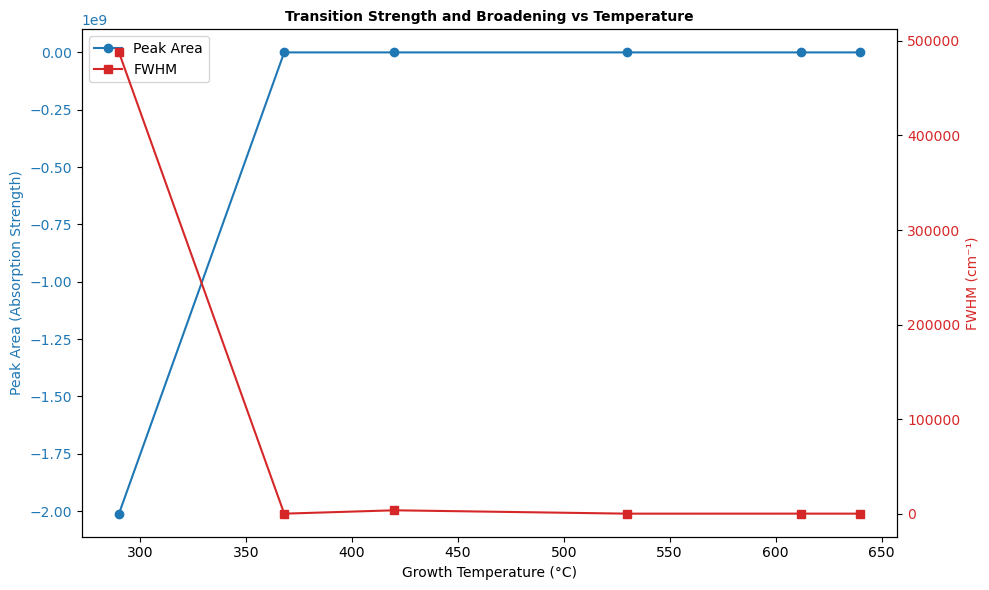

In [ ]:
# Cell 5: Peak Area and FWHM Trends
temperatures, areas, fwhms = [], [], []

for sample_name, results in sorted_samples:
    if results.get('parameters'):
        temp = get_sample_temp(sample_name)
        amp = results['parameters']['amplitude']
        hwhm = results['parameters']['FWHM'] / 2
        
        temperatures.append(temp)
        areas.append(np.pi * amp * hwhm) # Area under Lorentzian
        fwhms.append(hwhm * 2)

fig_analysis, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()
line1 = ax1.plot(temperatures, areas, 'o-', color='tab:blue', label='Peak Area')
ax1.set_xlabel('Growth Temperature (°C)')
ax1.set_ylabel('Peak Area (Absorption Strength)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
line2 = ax2.plot(temperatures, fwhms, 's-', color='tab:red', label='FWHM')
ax2.set_ylabel('FWHM (cm⁻¹)', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')
plt.title('Transition Strength and Broadening vs Temperature', fontsize='medium', fontweight='bold')
fig_analysis.tight_layout()
plt.show()